In [1]:
import os
import sys
from pathlib import Path
import aperturePhot as ap
import astropy.units as astunit
import ccdproc as ccdp
import gain_noise
import numpy as np
import photutils.aperture
import plateSolve
import pandas as pd
from astropy.nddata import CCDData
from astropy.coordinates import SkyCoord
from astropy.table import Table
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from collections import OrderedDict 

datadir = '/home/neo/Astro_Lab/Data/Stacked_Images/'
path = Path(datadir)
os.chdir(path)


In [2]:

R_band = pd.read_csv("R_band.csv",sep=',')
V_band = pd.read_csv("V_band.csv",sep=',')

ra_R = R_band["RA"]
dec_R = R_band["DEC"]
ra_V = V_band["RA"]
dec_V = V_band["DEC"]
mag_R = R_band["mag"]
mag_R_err = R_band["err"]
mag_V = V_band["mag"]
mag_V_err = V_band["err"]


In [3]:
gaia_Gmag = 14.5351
gaia_Gmag_err = 0.0004
gaia_BP_RP = 1.2375
gaia_BP_err = 0.0025
gaia_RP_err = 0.0017

gaia_R_mag = gaia_Gmag + 0.003226 - 0.3833*gaia_BP_RP + 0.1346*gaia_BP_RP**2
gaia_V_mag = gaia_Gmag + 0.01760 + 0.006860*gaia_BP_RP + 0.1732*gaia_BP_RP**2

gaia_BP_RP_err = np.sqrt(gaia_BP_err**2+gaia_RP_err**2)
gaia_R_err = np.sqrt(gaia_Gmag_err**2 + (-0.3833+2*0.1346*gaia_BP_RP)**2*gaia_BP_RP_err**2)
gaia_V_err = np.sqrt(gaia_Gmag_err**2 + (0.006860+2*.1732*gaia_BP_RP)**2*gaia_BP_RP_err**2)

R_mag = -3.9080
R_mag_err = 0.11622
V_mag = -3.10075
V_mag_err = 0.05400



cali_factor_R = gaia_R_mag - R_mag
cali_factor_R_err = np.sqrt(gaia_R_err**2 + R_mag_err**2)
cali_factor_V = gaia_R_mag - R_mag
cali_factor_V_err = np.sqrt(gaia_V_err**2 + V_mag_err**2)

In [4]:

cali_mag_R = mag_R + cali_factor_R
cali_magR_err = np.sqrt(mag_R_err**2 + cali_factor_R_err**2)

cali_mag_V = mag_V + cali_factor_V
cali_magV_err = np.sqrt(mag_V_err**2 + cali_factor_V_err**2)
#print(cali_magR_err)

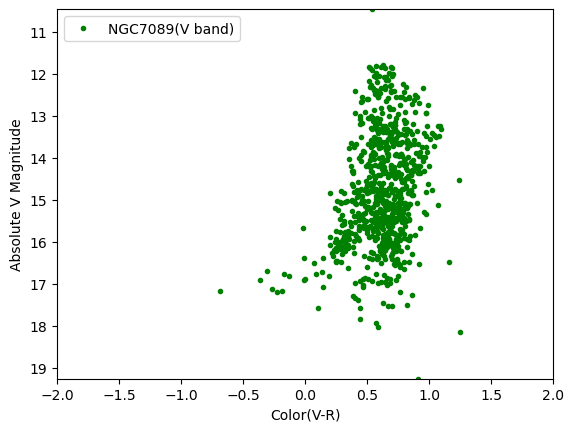

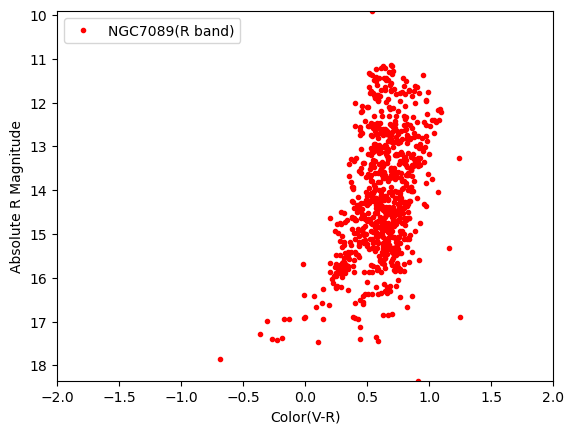

In [10]:
x = cali_mag_V-cali_mag_R
x_err = np.sqrt(cali_magV_err**2+cali_magR_err**2)
#x_err = 
V = cali_mag_V
R = cali_mag_R
plt.xlim(-2,2)
plt.xlabel("Color(V-R)")
plt.ylim(max(V),min(V))
plt.ylabel("Absolute V Magnitude")
plt.plot(x,V,'.',color = 'g',label='NGC7089(V band)')
#plt.errorbar(x,V,xerr = x_err, yerr = cali_magV_err,fmt ='o')
#plt.errorbar(x,V,yerr = cali_magV_err,fmt ='o')
plt.legend()
plt.show()
plt.xlim(-2,2)
plt.xlabel("Color(V-R)")
plt.ylim(max(R),min(R))
plt.ylabel("Absolute R Magnitude")
plt.plot(x,R,'.',color='r',label='NGC7089(R band)')
#plt.errorbar(x,R,yerr = y_error,fmt ='o')
plt.legend()
plt.show()



In [11]:
datadir = '/home/neo/Astro_Lab/Data/Stacked_Images/Isochrones/'
path = Path(datadir)
os.chdir(path)

In [13]:
# Reading the isochornes
datafiles = ['0_0000981164.dat','0_0003901863.dat','0_0015467043.dat','0_0060542748.dat','0_0225940079.dat','0_0001075787.dat',\
        '0_0004277712.dat','0_0016949919.dat','0_0066240673.dat','0_0245756645.dat','0_0001179532.dat','0_0004689702.dat','0_0018573981.dat',\
            '0_0072460149.dat','0_0267123853.dat','0_0001293277.dat','0_0005141295.dat','0_0020352473.dat','0_0079246035.dat','0_0290129497.dat',\
                '0_0001417984.dat','0_0005636284.dat','0_0022299845.dat','0_0086646489.dat','0_0314860388.dat','0_0001554710.dat','0_0006178820.dat',\
                    '0_0024431849.dat','0_0094713095.dat','0_0341401114.dat','0_0001704611.dat','0_0006773447.dat','0_0026765651.dat','0_0103500980.dat',\
                         '0_0369832629.dat','0_0001868956.dat','0_0007425142.dat','0_0029319944.dat','0_0113068898.dat','0_0400230658.dat',\
                            '0_0002049132.dat','0_0008139350.dat','0_0032115074.dat','0_0123479292.dat','0_0432663940.dat','0_0002246665.dat',\
                                '0_0008922028.dat','0_0035173163.dat','0_0134798300.dat','0_0467192323.dat','0_0002463221.dat','0_0009779695.dat',\
                                    '0_0038518253.dat','0_0147095729.dat','0_0503864738.dat','0_0002700631.dat','0_0010719481.dat','0_0042176445.dat',\
                                        '0_0160444951.dat','0_0542717089.dat','0_0002960898.dat','0_0011749182.dat','0_0046176044.dat','0_0174922738.dat',\
                                            '0_0583770118.dat','0_0003246217.dat','0_0012877322.dat','0_0050547722.dat','0_0190609002.dat',\
                                                '0_0003558993.dat','0_0014113216.dat','0_0055324667.dat','0_0207586443.dat']


for it in range(0,len(datafiles)):
   
    print('Reading file: ',it,'. ',datafiles[it])
    iso_data = pd.read_csv(datafiles[it],sep='\s+',comment='#')
    iso_data.columns =['z', 'mh', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag']

    age = np.array(iso_data["logAge"])
    age_trimmed = list(OrderedDict.fromkeys(age)) 
    z = iso_data["mh"][1]

    file = open("Datas/00000_metallicity_age.txt" , "a")

    for i in range(0,len(age_trimmed)):
        file.write("%2.8f\t %2.8f\n" % (z,age_trimmed[i]))
    file.close()

    gm = iso_data['Gmag']
    bp = iso_data['G_BPmag']
    rp = iso_data['G_RPmag']

    r = gm + 0.003226 - 0.3833*(bp-rp) + 0.1346*(bp-rp)**2
    v = gm + 0.01760 + 0.006860*(bp-rp) + 0.1732*(bp-rp)**2

    v_r = v - r
    r = np.array(r)
    v = np.array(v)
    v_r = np.array(v_r)
    for i in range(0,len(age_trimmed)):

        file_name = "{:.6f}".format(z) +'_'+ "{:2.6f}".format(age_trimmed[i]) + ".dat"
        file_x = open("Datas/"+file_name, "w")
        print("writing file for age: " , age_trimmed[i],end='\r')
        for j in range(0,len(age)):
            if(age[j]==age_trimmed[i]):
                file_x.write("%2.8f\t %2.8f\t %2.8f\n" % (r[j],v[j],v_r[j]))
        file_x.close()
    #print('Number of files created: ',len(age_trimmed))

Reading file:  0 .  0_0000981164.dat
Reading file:  1 .  0_0003901863.dat
Reading file:  2 .  0_0015467043.dat
Reading file:  3 .  0_0060542748.dat
Reading file:  4 .  0_0225940079.dat
Reading file:  5 .  0_0001075787.dat
Reading file:  6 .  0_0004277712.dat
Reading file:  7 .  0_0016949919.dat
Reading file:  8 .  0_0066240673.dat
Reading file:  9 .  0_0245756645.dat
Reading file:  10 .  0_0001179532.dat
Reading file:  11 .  0_0004689702.dat
Reading file:  12 .  0_0018573981.dat
Reading file:  13 .  0_0072460149.dat
Reading file:  14 .  0_0267123853.dat
Reading file:  15 .  0_0001293277.dat
Reading file:  16 .  0_0005141295.dat
Reading file:  17 .  0_0020352473.dat
Reading file:  18 .  0_0079246035.dat
Reading file:  19 .  0_0290129497.dat
Reading file:  20 .  0_0001417984.dat
Reading file:  21 .  0_0005636284.dat
Reading file:  22 .  0_0022299845.dat
Reading file:  23 .  0_0086646489.dat
Reading file:  24 .  0_0314860388.dat
Reading file:  25 .  0_0001554710.dat
Reading file:  26 .  0

Max_age =  10.50002
Min_age =  5.0
Max_metallicity =  0.68
Min_metallicity =  -2.19174


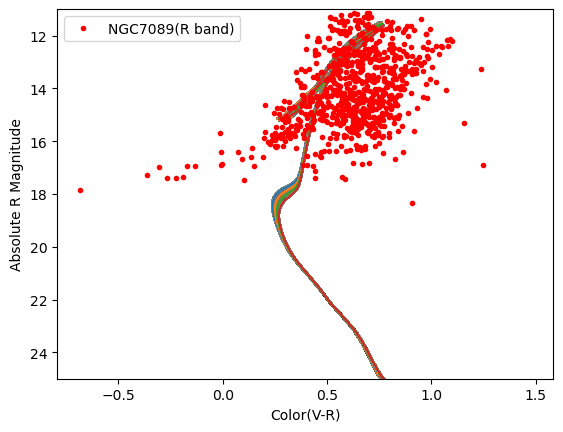

In [17]:
n_met,n_age = np.loadtxt('Datas/metallicity_age.txt',usecols =(0,1),unpack = True)
n_met = list(OrderedDict.fromkeys(n_met)) 
print("Max_age = ",max(n_age))
print("Min_age = ",min(n_age))
print("Max_metallicity = ",max(n_met))
print("Min_metallicity = ",min(n_met))

age_max = 10.2
age_min = 10.0
met_max = -1.6
met_min = -1.7

d_mod = 15

for p in n_met:
    for q in n_age:
        if( p < met_max and p > met_min and q < age_max and q > age_min):
            name = str("{:.6f}".format(p))+'_'+str("{:2.6f}".format(q))+'.dat'
            #print(name)
            m_r,m_v,m_v_r = np.loadtxt('Datas/'+name,usecols =(0,1,2),unpack = True)
            m_r = m_r + d_mod
            m_v = m_v + d_mod
            plt.plot(m_v_r,m_r,'-',markersize=0.2)
            #plt.plot(m_v_r,m_v,'-',markersize=0.2)
            #plt.ylim(max(m_r),min(m_r))
            #plt.ylim(max(R),min(R))
            plt.ylim(25,11)
plt.xlabel("Color(V-R)")
#plt.ylim(max(R),min(R))
plt.ylabel("Absolute R Magnitude")
#plt.ylabel("Absolute V Magnitude")
plt.plot(x,R,'.',color='r',label='NGC7089(R band)')
#plt.plot(x,V,'.',color='g',label='NGC7089(G band)')
plt.legend()
plt.show()
